# How much prescribed connectivity can a simple graph retain?

This notebook extends the degree-repair experiments in four directions: retained-connectivity scaling, random-erasure efficiency, cutoff intervention, and the location of optimal repair. Experiment loops and analysis are here; `utils.py` supplies sampling, statistics, caching and exact optimisation. `graphicality.py` preserves the previous numerical core.

**Run:** install `requirements.txt`, select the Python kernel, then Run All. `MODE='quick'` is a complete exploratory run; switch to `'full'` for the planned larger experiment. Results are cached per sample and exported as CSV and figures. Previously supplied full-run data are retained in `baseline/`; they are analysed separately from new samples.

In [13]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import graphicality as gp
import utils as u

MODE = 'full'
SEED = 5441
assert MODE in {'quick', 'full'}
CFG = dict(
    sizes=[100, 300, 1000, 3000, 10000] if MODE == 'quick' else [1000, 3000, 10000, 30000, 100000],
    gammas=[1.3, 1.5, 1.8], repeats=20 if MODE == 'quick' else 100,
    erase_sizes=[100, 300, 1000] if MODE == 'quick' else [200, 500, 1000, 3000],
    erase_gammas=[1.3, 1.5, 1.8, 2.5], erase_repeats=10 if MODE == 'quick' else 100,
    pairings=3 if MODE == 'quick' else 5,
    cutoff_sizes=[100, 300, 1000] if MODE == 'quick' else [100, 300, 1000, 3000, 10000],
    cutoff_gammas=[1.3, 1.8], cutoff_repeats=15 if MODE == 'quick' else 100,
    profile_n=24 if MODE == 'quick' else 40,
    bootstraps=300 if MODE == 'quick' else 1000,
)
OUT = Path('results') / MODE
OUT.mkdir(parents=True, exist_ok=True)
cache = u.Cache(OUT / 'sample_cache', SEED)
u.metadata(OUT / 'run_parameters.json', CFG, SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
display(pd.Series(CFG, name='design').to_frame())

,design
sizes,"[1000, 3000, 10000, 30000, 100000]"
gammas,"[1.3, 1.5, 1.8]"
repeats,100
erase_sizes,"[200, 500, 1000, 3000]"
erase_gammas,"[1.3, 1.5, 1.8, 2.5]"
erase_repeats,100
pairings,5
cutoff_sizes,"[100, 300, 1000, 3000, 10000]"
cutoff_gammas,"[1.3, 1.8]"
cutoff_repeats,100


## Definitions and scope

For sorted targets $d_1\ge\cdots\ge d_n$, put $S=\sum_i d_i$,
$$
\Delta_k=k(k-1)+\sum_{i>k}\min(k,d_i)-\sum_{i\le k}d_i,
\qquad F=\max(0,-\min_k\Delta_k).
$$
The previous core computes the minimum degree discrepancy as $Q=2\lceil F/2\rceil$. This sharp deficit identity is an imported mathematical input; the small-instance MILP below independently checks its numerical application, rather than proving it in general.

Let $E_{\max}=\max\{|E(G)|:\deg_G(i)\le d_i\}$. An optimum for degree discrepancy can be chosen under the degree caps, so $S-Q=2E_{\max}$. Thus $1-Q/S$ is the maximum retained fraction under degree reductions. It does not describe every optimal repair, which can also include increases.

In a randomly paired and erased graph let $D=S-2|E_{\rm erased}|$. Then
$$
g=(D-Q)/S,\qquad
\eta=(S-D)/(S-Q)=|E_{\rm erased}|/E_{\max}.
$$
The latter is undefined when $E_{\max}=0$; such targets are counted and omitted from its mean. All sampling below rejects the entire odd-sum target, preserving the specified conditional law.

## 1. Retained-connectivity scaling

**Question.** For fixed $1<\gamma<2$, what scale of connectivity survives optimal repair?

With support $1,\ldots,n-1$, $S=\Theta_{\mathbb P}(n^{3-\gamma})$. For $t=\lceil n^{1/\gamma}\rceil$, define $m=\#\{i:d_i\ge t\}$ and $B=\sum_{d_i<t}d_i$. Every capped graph satisfies
$$
E_{\max}\le B+\binom m2.
$$
A clique on $\ell=\min(m,t+1)$ high-degree vertices is feasible, giving $E_{\max}\ge\binom\ell2$. Tail counting and concentration give $m=\Theta_{\mathbb P}(n^{1/\gamma})$, while $B=O_{\mathbb P}(n^{2/\gamma})$. Consequently
$$
E_{\max}=\Theta_{\mathbb P}(n^{2/\gamma}),\qquad
1-Q/S=\Theta_{\mathbb P}(n^{-r(\gamma)}),\qquad
r(\gamma)=\frac{(\gamma-1)(2-\gamma)}{\gamma}.
$$
This order statement does not assert a limiting constant. We test bounded rescaled behaviour and show the deterministic bounds on each sampled target.

In [14]:
records = []
for n in CFG['sizes']:
    for gamma in CFG['gammas']:
        for rep in range(CFG['repeats']):
            def compute(n=n, gamma=gamma, rep=rep):
                d = u.sample(n, gamma, u.rng(SEED, 'scaling', n, gamma, rep))
                return dict(n=n, gamma=gamma, rep=rep, **u.measure(d, gamma))
            records.append(cache.get('scaling', [n, gamma, rep], compute))
    print(f'Scaling: n={n} complete')
scaling = pd.DataFrame(records)
scaling.to_csv(OUT / 'scaling_targets.csv', index=False)
scale_summary = u.summarise(scaling, ['n', 'gamma'],
    ['retained', 'E_max', 'E_scaled', 'retained_scaled', 'lower_scaled', 'upper_scaled'],
    SEED, CFG['bootstraps'])
scale_summary.to_csv(OUT / 'scaling_summary.csv', index=False)
display(scale_summary[['n', 'gamma', 'targets', 'retained', 'E_scaled', 'retained_scaled']])

Scaling: n=1000 complete
Scaling: n=3000 complete
Scaling: n=10000 complete
Scaling: n=30000 complete
Scaling: n=100000 complete


,n,gamma,targets,retained,E_scaled,retained_scaled
0,1000,1.3,100,0.668004,0.412288,2.038893
1,1000,1.5,100,0.703431,0.836475,2.224445
2,1000,1.8,100,0.891630,1.691191,1.647598
3,3000,1.3,100,0.588101,0.413952,2.143584
4,3000,1.5,100,0.612962,0.877630,2.327843
5,3000,1.8,100,0.837638,1.841899,1.706607
6,10000,1.3,100,0.505184,0.428731,2.236678
7,10000,1.5,100,0.508931,0.903165,2.362247
8,10000,1.8,100,0.790498,1.980527,1.792489
9,30000,1.3,100,0.441118,0.440350,2.332287


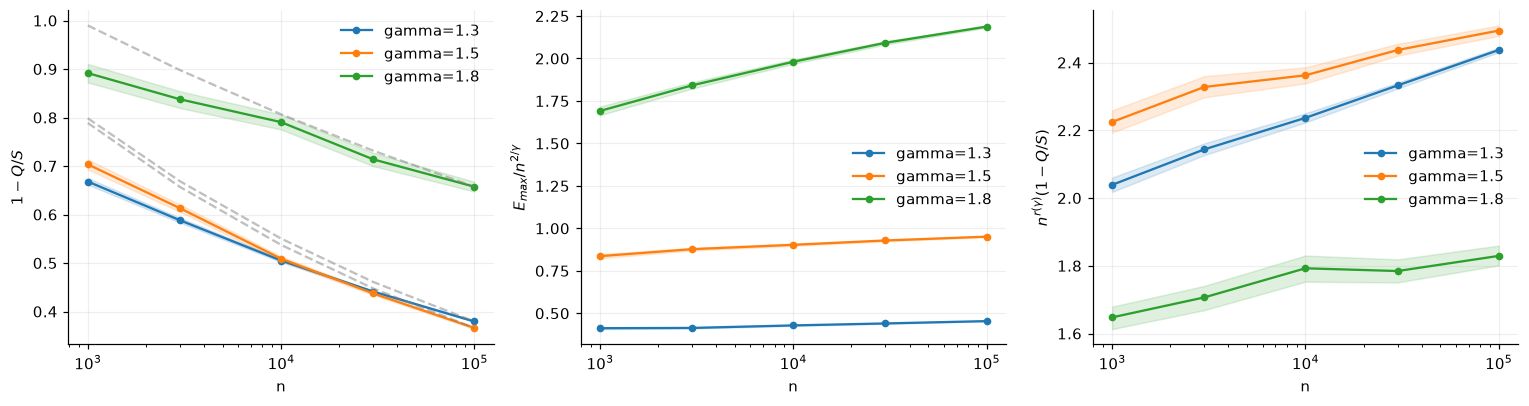

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
u.lines(axes[0], scale_summary, 'n', 'retained', logx=True, logy=False)
u.lines(axes[1], scale_summary, 'n', 'E_scaled', logx=True)
u.lines(axes[2], scale_summary, 'n', 'retained_scaled', logx=True)
axes[0].set_ylabel(r'$1-Q/S$')
axes[1].set_ylabel(r'$E_{max}/n^{2/\gamma}$')
axes[2].set_ylabel(r'$n^{r(\gamma)}(1-Q/S)$')
for gamma, part in scale_summary.groupby('gamma'):
    part = part.sort_values('n')
    reference = part.retained.iloc[-1]*(part.n.to_numpy()/part.n.iloc[-1])**(-u.rate(gamma))
    axes[0].plot(part.n, reference, '--', color='grey', alpha=.5)
u.savefig(fig, OUT, '01_retained_scaling')

**Read the figure.** Dashed curves are theoretical slopes anchored at the largest sampled size, not fitted laws. Flat rescaled means would support a stronger constant-limit hypothesis; bounded non-flat curves are compatible with the order theorem. Confidence bands cover Monte Carlo uncertainty only. They exclude finite-size bias and uncertainty in the mathematical model.

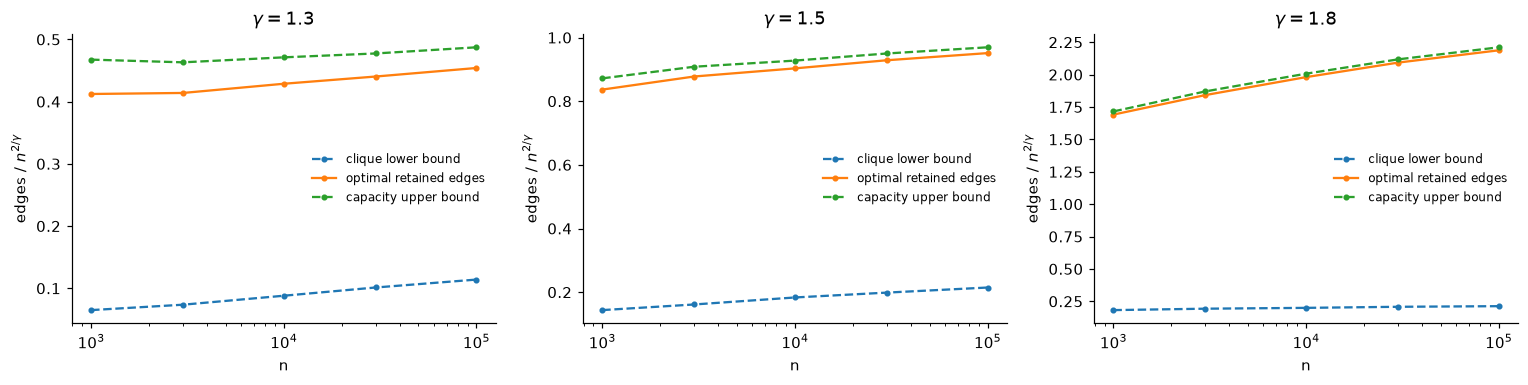

In [16]:
fig, axes = plt.subplots(1, len(CFG['gammas']), figsize=(14, 3.6))
for ax, (gamma, part) in zip(axes, scale_summary.groupby('gamma')):
    for metric, label, style in [('lower_scaled', 'clique lower bound', '--'),
                                  ('E_scaled', 'optimal retained edges', '-'),
                                  ('upper_scaled', 'capacity upper bound', '--')]:
        ax.plot(part.n, part[metric], style, marker='o', ms=3, label=label)
    ax.set(xscale='log', xlabel='n', ylabel=r'edges / $n^{2/\gamma}$', title=fr'$\gamma={gamma}$')
    ax.legend(frameon=False, fontsize=8)
u.savefig(fig, OUT, '02_samplewise_bounds')
assert (scaling.E_lower <= scaling.E_max).all()
assert (scaling.E_max <= scaling.E_upper).all()

**Finite-size diagnostic.** Estimate log–log slopes using the largest three sizes. Bootstrap independent targets separately within each size. Agreement is diagnostic, not proof; estimates can remain biased even with narrow intervals. The order theorem alone does not guarantee convergence of fitted slopes to this power-law reference.

In [17]:
slope_rows = []
for gamma, part in scaling.groupby('gamma'):
    sizes = sorted(part.n.unique())[-3:]
    groups = [part.loc[part.n.eq(n), 'retained'].to_numpy() for n in sizes]
    if any(np.any(x <= 0) for x in groups):
        raise ValueError('Log-slope diagnostic needs strictly positive retained fractions.')
    x = np.log(sizes)
    estimate = np.polyfit(x, np.log([g.mean() for g in groups]), 1)[0]
    generator = u.rng(SEED, 'slope', gamma)
    draws = [np.polyfit(x, np.log([generator.choice(g, len(g), replace=True).mean()
                                 for g in groups]), 1)[0] for _ in range(CFG['bootstraps'])]
    lo, hi = np.quantile(draws, [.025, .975])
    slope_rows.append(dict(gamma=gamma, predicted=-u.rate(gamma), estimate=estimate, lo=lo, hi=hi,
                           smallest_n=min(sizes), largest_n=max(sizes)))
slopes = pd.DataFrame(slope_rows)
slopes.to_csv(OUT / 'scaling_slopes.csv', index=False)
display(slopes.round(4))

,gamma,predicted,estimate,lo,hi,smallest_n,largest_n
0,1.3,-0.1615,-0.1243,-0.1270,-0.1214,10000,100000
1,1.5,-0.1667,-0.1431,-0.1485,-0.1379,10000,100000
2,1.8,-0.0889,-0.0799,-0.0913,-0.0689,10000,100000


## 2. Random-erasure efficiency

**Question.** Does random pairing retain a substantial fraction of what is achievable?

The original additive gap satisfies $0\le g\le1-Q/S$, so it vanishes automatically if $Q/S\to1$. In contrast, $\eta$ compares surviving edge counts directly. No limiting value of $\eta$ is assumed here.

First reanalyse the supplied full-run pairings. These are historical data from a separate target stream; they are not pooled with the new experiment. Ratios are computed within each target before averaging. Pairings share a target and are not treated as independent target observations.

,n,gamma,targets,eta,eta_lo,eta_hi,gap
0,200,0.5,200,0.709989,0.708799,0.711189,0.268856
1,200,1.3,200,0.745921,0.743312,0.748812,0.204978
2,200,1.8,200,0.761721,0.754844,0.768879,0.225410
3,200,2.5,200,0.953034,0.946465,0.959476,0.046839
4,500,0.5,200,0.708854,0.707994,0.709696,0.268977
5,500,1.3,200,0.750697,0.748513,0.752852,0.180663
6,500,1.8,200,0.733117,0.728548,0.737890,0.245546
7,500,2.5,200,0.957472,0.950159,0.963862,0.042479
8,1000,0.5,200,0.709687,0.709123,0.710253,0.266907
9,1000,1.3,200,0.752333,0.750769,0.753767,0.167001


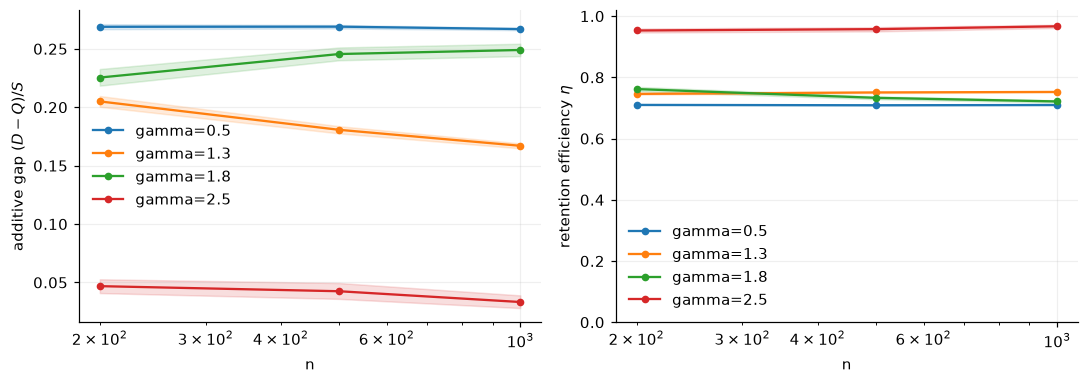

In [26]:
baseline_pairs = u.efficiency(pd.read_csv('baseline/erasure_pairings.csv'))
metrics = ['eta', 'retained', 'erased_retained', 'gap', 'loop_loss', 'parallel_loss']
baseline_targets = baseline_pairs.groupby(['n', 'gamma', 'rep'], as_index=False)[metrics].mean()
baseline_targets['graphical'] = baseline_pairs.groupby(['n', 'gamma', 'rep']).Q.first().to_numpy() == 0
baseline_summary = u.summarise(baseline_targets, ['n', 'gamma'], metrics, SEED, CFG['bootstraps'])
baseline_targets.to_csv(OUT / 'baseline_efficiency_targets.csv', index=False)
baseline_summary.to_csv(OUT / 'baseline_efficiency_summary.csv', index=False)
display(baseline_summary[['n', 'gamma', 'targets', 'eta', 'eta_lo', 'eta_hi', 'gap']])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
u.lines(axes[0], baseline_summary, 'n', 'gap', logx=True)
u.lines(axes[1], baseline_summary, 'n', 'eta', logx=True)
axes[0].set_ylabel(r'additive gap $(D-Q)/S$')
axes[1].set(ylabel=r'retention efficiency $\eta$', ylim=(0, 1.02))
u.savefig(fig, OUT, '03_existing_erasure_efficiency')

**New design.** Use independent targets for each size and exponent, with repeated uniform stub pairings per target. Target seeds and pairing seeds are separate. The explicit stub limit stops an unexpectedly large pairing instead of silently omitting it. Sparse $\gamma=2.5$ serves as a comparison; the retained-scaling theorem is only for $1<\gamma<2$.

In [27]:
pair_records = []
for n in CFG['erase_sizes']:
    for gamma in CFG['erase_gammas']:
        for rep in range(CFG['erase_repeats']):
            d = u.sample(n, gamma, u.rng(SEED, 'erasure-target', n, gamma, rep))
            for pairing in range(CFG['pairings']):
                def compute(d=d, n=n, gamma=gamma, rep=rep, pairing=pairing):
                    return dict(n=n, gamma=gamma, rep=rep, pairing=pairing,
                        **u.erasure_row(d, u.rng(SEED, 'pairing', n, gamma, rep, pairing)))
                row = cache.get('pairing', [n, gamma, rep, pairing], compute)
                assert row['S'] == int(d.sum())
                pair_records.append(row)
    print(f'Erasure: n={n} complete')
pairs = u.efficiency(pd.DataFrame(pair_records))
pairs.to_csv(OUT / 'erasure_pairings.csv', index=False)
erasure_targets = pairs.groupby(['n', 'gamma', 'rep'], as_index=False)[metrics].mean()
erasure_targets['graphical'] = pairs.groupby(['n', 'gamma', 'rep']).Q.first().to_numpy() == 0
erasure_summary = u.summarise(erasure_targets, ['n', 'gamma'], metrics, SEED, CFG['bootstraps'])
erasure_targets.to_csv(OUT / 'erasure_targets.csv', index=False)
erasure_summary.to_csv(OUT / 'erasure_summary.csv', index=False)
print('Undefined efficiency observations:', int(pairs.eta.isna().sum()))
display(erasure_summary[['n', 'gamma', 'targets', 'eta', 'eta_lo', 'eta_hi']])

Erasure: n=200 complete
Erasure: n=500 complete
Erasure: n=1000 complete
Erasure: n=3000 complete
Undefined efficiency observations: 0


,n,gamma,targets,eta,eta_lo,eta_hi
0,200,1.3,100,0.747225,0.743061,0.751086
1,200,1.5,100,0.743028,0.738771,0.747468
2,200,1.8,100,0.758861,0.749571,0.769334
3,200,2.5,100,0.952255,0.945017,0.960082
4,500,1.3,100,0.749296,0.746597,0.751741
5,500,1.5,100,0.746170,0.742350,0.750612
6,500,1.8,100,0.738228,0.731317,0.745968
7,500,2.5,100,0.956861,0.945818,0.965513
8,1000,1.3,100,0.754911,0.752756,0.757166
9,1000,1.5,100,0.745573,0.742444,0.748566


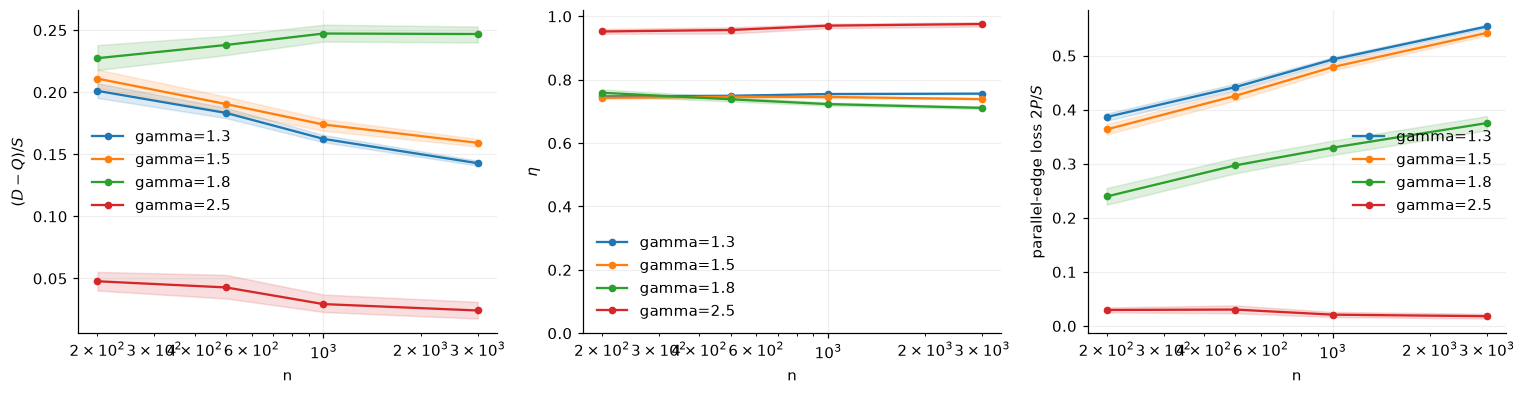

,n,gamma,graphical,targets,eta,eta_lo,eta_hi
0,200,1.3,False,100,0.747225,0.743681,0.751045
1,200,1.5,False,97,0.743369,0.738801,0.747973
2,200,1.5,True,3,0.732006,0.727305,0.736320
3,200,1.8,False,50,0.732489,0.726200,0.738758
4,200,1.8,True,50,0.785234,0.769163,0.802301
5,200,2.5,True,100,0.952255,0.943882,0.959535
6,500,1.3,False,100,0.749296,0.746859,0.751844
7,500,1.5,False,100,0.746170,0.742523,0.750126
8,500,1.8,False,66,0.725682,0.720780,0.730577
9,500,1.8,True,34,0.762580,0.748475,0.778224


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.7))
u.lines(axes[0], erasure_summary, 'n', 'gap', logx=True)
u.lines(axes[1], erasure_summary, 'n', 'eta', logx=True)
u.lines(axes[2], erasure_summary, 'n', 'parallel_loss', logx=True)
axes[0].set_ylabel(r'$(D-Q)/S$')
axes[1].set(ylabel=r'$\eta$', ylim=(0, 1.02))
axes[2].set_ylabel(r'parallel-edge loss $2P/S$')
u.savefig(fig, OUT, '04_new_erasure_efficiency')
conditional = u.summarise(erasure_targets, ['n', 'gamma', 'graphical'], ['eta'], SEED, CFG['bootstraps'])
conditional.to_csv(OUT / 'erasure_conditioned.csv', index=False)
display(conditional[['n', 'gamma', 'graphical', 'targets', 'eta', 'eta_lo', 'eta_hi']])

**Interpretation.** A falling additive gap accompanied by stable or falling efficiency demonstrates why total-degree normalisation alone is insufficient. Any trend in efficiency remains a finite-size finding. The conditional table separates exactly graphical targets from infeasible ones, but small subgroup counts cannot support precise comparisons. Missing intervals flag singleton or constant samples; they do not certify zero population uncertainty.

## 3. Cutoff intervention

**Question.** How much must we restrict the tail to restore exact or approximate feasibility?

Sample the same conditional law on $1,\ldots,K_n$, where $K_n=\min(n-1,\lfloor n^\alpha\rfloor)$. We vary $\alpha$ near $1/\gamma$, the known cutoff scale for graphicality constraints, and include the original $\alpha=1$ model. Boundary behaviour can depend on constants and finite-size effects; no exact transition at finite $n$ is assumed.
 
Record both $\Pr(Q=0)$ and $\mathbb E[Q/S]$. Exact feasibility and a small relative repair cost are different properties. We also record the realised support cutoff, which is affected by rounding.

In [21]:
cutoff_records = []
for gamma in CFG['cutoff_gammas']:
    offsets = [-.15, 0, .15] if MODE == 'quick' else [-.15, -.075, 0, .075, .15]
    alphas = sorted(set(round(float(np.clip(1/gamma + delta, .1, 1)), 6)
                        for delta in offsets) | {1.})
    for n in CFG['cutoff_sizes']:
        for alpha in alphas:
            for rep in range(CFG['cutoff_repeats']):
                def compute(n=n, gamma=gamma, alpha=alpha, rep=rep):
                    d = u.sample(n, gamma, u.rng(SEED, 'cutoff', n, gamma, alpha, rep), alpha)
                    support, _ = u.law(n, gamma, alpha)
                    return dict(n=n, gamma=gamma, alpha=alpha, rep=rep, K=int(support[-1]),
                                **gp.eg_summary(d))
                cutoff_records.append(cache.get('cutoff', [n, gamma, alpha, rep], compute))
    print(f'Cutoff: gamma={gamma} complete')
cutoffs = pd.DataFrame(cutoff_records)
cutoffs.to_csv(OUT / 'cutoff_targets.csv', index=False)
cutoff_summary = u.summarise(cutoffs, ['n', 'gamma', 'alpha'], ['a'], SEED, CFG['bootstraps'])
cutoff_summary.to_csv(OUT / 'cutoff_summary.csv', index=False)
display(cutoff_summary[['n', 'gamma', 'alpha', 'targets', 'a', 'p_graphical', 'p_graphical_lo', 'p_graphical_hi']])

Cutoff: gamma=1.3 complete
Cutoff: gamma=1.8 complete


,n,gamma,alpha,targets,a,p_graphical,p_graphical_lo,p_graphical_hi
0,100,1.3,0.619231,100,0.000000,1.00,9.630065e-01,1.000000
1,100,1.3,0.694231,100,0.000000,1.00,9.630065e-01,1.000000
2,100,1.3,0.769231,100,0.000000,1.00,9.630065e-01,1.000000
3,100,1.3,0.844231,100,0.001131,0.97,9.154806e-01,0.989745
4,100,1.3,0.919231,100,0.029998,0.49,3.942200e-01,0.586520
5,100,1.3,1.000000,100,0.142224,0.09,4.807254e-02,0.162262
6,100,1.8,0.405556,100,0.000000,1.00,9.630065e-01,1.000000
7,100,1.8,0.480556,100,0.000000,1.00,9.630065e-01,1.000000
8,100,1.8,0.555556,100,0.000000,1.00,9.630065e-01,1.000000
9,100,1.8,0.630556,100,0.000000,1.00,9.630065e-01,1.000000


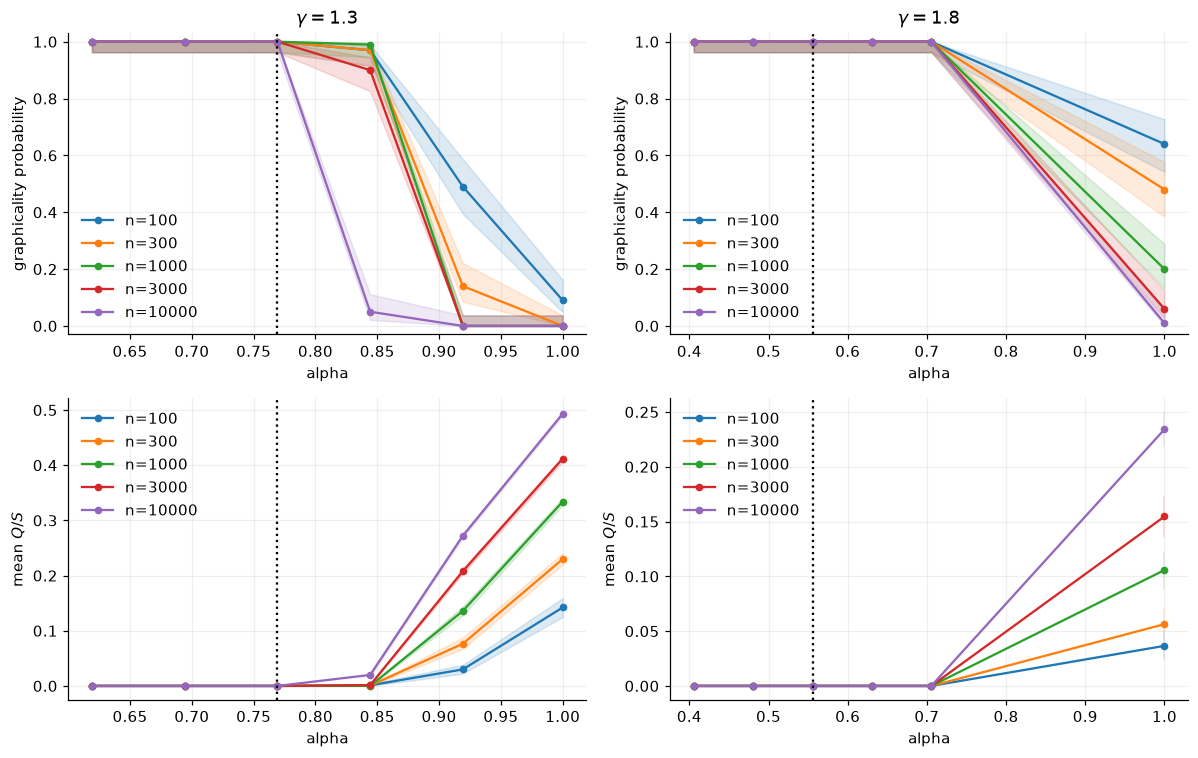

In [22]:
fig, axes = plt.subplots(2, len(CFG['cutoff_gammas']), figsize=(11, 7), squeeze=False)
for j, gamma in enumerate(CFG['cutoff_gammas']):
    table = cutoff_summary[cutoff_summary.gamma.eq(gamma)]
    u.lines(axes[0, j], table, 'alpha', 'p_graphical', group='n')
    u.lines(axes[1, j], table, 'alpha', 'a', group='n')
    axes[0, j].set(title=fr'$\gamma={gamma}$', ylabel='graphicality probability', ylim=(-.03, 1.03))
    axes[1, j].set_ylabel(r'mean $Q/S$')
    for ax in axes[:, j]:
        ax.axvline(1/gamma, color='black', linestyle=':', label=r'$1/\gamma$')
u.savefig(fig, OUT, '05_cutoff_intervention')

**Interpretation.** A region with low graphicality probability but small repair cost would show that binary feasibility overstates the practical distortion. A shifted crossing at these sample sizes is not evidence against an asymptotic cutoff law. Increase replications around ambiguous cells rather than filling a large phase diagram uniformly.

## 4. Where does optimal repair occur?

**Question.** Are hubs necessarily responsible for most degree reductions, or does the answer depend on which optimum we choose?

For an optimal capped graph write $r_i=d_i-\deg_G(i)$ and $R$k$=\sum_{i\le k}r_i/Q$. We solve a binary edge optimisation to maximise edge count. Then, fixing that optimum edge count, minimise and maximise top-$k$ repair. These are exact extrema across capped optimal repairs. A single illustrated optimum need not attain all endpoint extrema simultaneously.

This small experiment deliberately selects the first nongraphical target in each deterministic seed stream. It illustrates geometry of optimal repairs, not their population frequency. Equal target degrees use the fixed array order; the envelope captures the available freedom over labelled optimal graphs.

,n,gamma,rep,Q,k,repair_min,repair_max,R_min,R_max
0,40,1.3,0,22,0,0,0,0.000000,0.000000
1,40,1.3,0,22,1,0,20,0.000000,0.909091
2,40,1.3,0,22,2,0,22,0.000000,1.000000
3,40,1.3,0,22,3,2,22,0.090909,1.000000
4,40,1.3,0,22,4,15,22,0.681818,1.000000
...,...,...,...,...,...,...,...,...,...
77,40,1.8,0,36,36,36,36,1.000000,1.000000
78,40,1.8,0,36,37,36,36,1.000000,1.000000
79,40,1.8,0,36,38,36,36,1.000000,1.000000
80,40,1.8,0,36,39,36,36,1.000000,1.000000


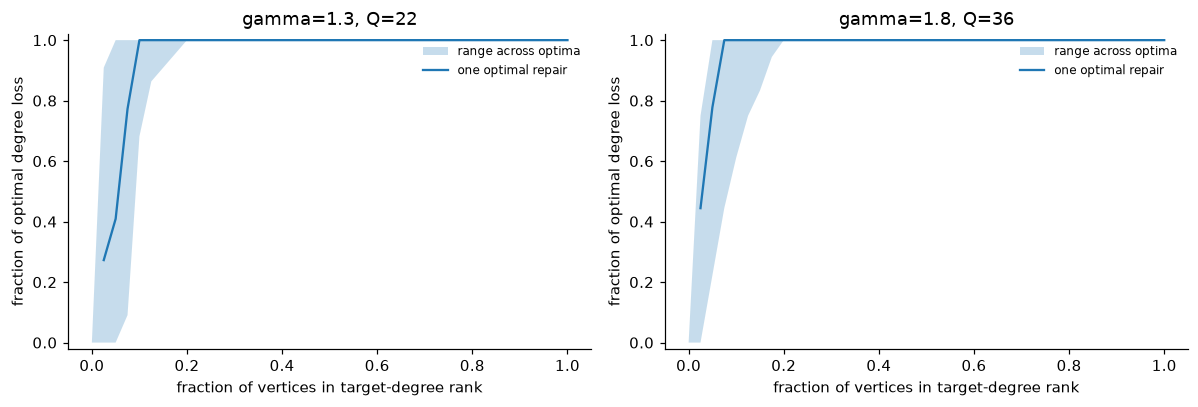

In [23]:
profile_rows, profile_examples = [], []
n = CFG['profile_n']
for gamma in [1.3, 1.8]:
    for rep in range(200):
        d = u.sample(n, gamma, u.rng(SEED, 'profile-target', n, gamma, rep))
        if gp.eg_summary(d)['Q'] > 0:
            break
    else:
        raise RuntimeError('No nongraphical example found; extend search or increase profile_n.')
    ks = list(range(n+1))
    exact = cache.get('profile', [n, gamma, rep, ks], lambda: u.capped_optimum(d, ks))
    assert exact['Q'] == gp.eg_summary(d)['Q']
    profile_examples.append(dict(n=n, gamma=gamma, rep=rep, target=d.tolist(), **exact))
    profile_rows.extend(dict(n=n, gamma=gamma, rep=rep, Q=exact['Q'], **row) for row in exact['envelope'])
profiles = pd.DataFrame(profile_rows)
profiles.to_csv(OUT / 'optimal_repair_envelopes.csv', index=False)
(OUT / 'optimal_repair_examples.json').write_text(json.dumps(profile_examples, indent=2))
display(profiles)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, example in zip(axes, profile_examples):
    part = profiles[profiles.gamma.eq(example['gamma'])]
    ax.fill_between(part.k/n, part.R_min, part.R_max, alpha=.25, label='range across optima')
    ax.plot(np.arange(1, n+1)/n, np.cumsum(example['repair'])/example['Q'], label='one optimal repair')
    ax.set(xlabel='fraction of vertices in target-degree rank', ylabel='fraction of optimal degree loss',
           title=f"gamma={example['gamma']}, Q={example['Q']}", ylim=(-.02, 1.02))
    ax.legend(frameon=False, fontsize=8)
u.savefig(fig, OUT, '06_optimal_repair_location')

**Interpretation.** A narrow envelope indicates that the target constrains where repair must occur. A wide envelope shows that a location claim based on one construction would be unreliable. These small examples cannot establish asymptotic hub concentration, and an obstruction index is not automatically a set of vertices that must lose degree.

## 5. Findings to take into the report

This table reports computed diagnostics without declaring convergence or novelty. The scaling theorem concerns fixed exponents strictly between 1 and 2 under the linear cutoff. Endpoint regimes and other cutoffs require separate analysis. Exact optimisation checks the repair identity on small instances; it does not replace a general proof.

In [24]:
findings = []
for gamma in CFG['gammas']:
    part = scale_summary[scale_summary.gamma.eq(gamma)].sort_values('n')
    last = part.iloc[-1]
    slope = slopes[slopes.gamma.eq(gamma)].iloc[0]
    findings.append(dict(experiment='scaling', gamma=gamma, n=int(last.n),
        observation=f"scaled retained mean={last.retained_scaled:.4g}; slope={slope.estimate:.3f}",
        qualification=f"predicted slope={slope.predicted:.3f}; finite-size diagnostic"))
for gamma, part in erasure_summary.groupby('gamma'):
    last = part.sort_values('n').iloc[-1]
    findings.append(dict(experiment='erasure', gamma=gamma, n=int(last.n),
        observation=f"mean targetwise efficiency={last.eta:.3f}; additive gap={last.gap:.3f}",
        qualification='No asymptotic efficiency limit established'))
findings = pd.DataFrame(findings)
findings.to_csv(OUT / 'findings.csv', index=False)
display(findings)
print(f'CSV tables, figures and sample cache: {OUT.resolve()}')
from IPython.display import Markdown
last_efficiency = erasure_summary.sort_values('n').groupby('gamma').tail(1)
values = '; '.join(f"gamma={row.gamma:g}: {row.eta:.1%}" for row in last_efficiency.itertuples())
display(Markdown(
    '**Computed interpretation.** At the largest newly paired size, mean targetwise '
    f'retention efficiencies are {values}. These compare retained edges with a target-specific '
    'optimum, rather than comparing losses with the much larger requested total. '
    'The scaling slope table and rescaled curves expose finite-size drift; an order theorem '
    'does not imply a constant limit or exact finite-range slope. The cutoff panels distinguish '
    'exact feasibility from small relative distortion. Profile envelopes describe all capped '
    'optima for the selected examples only.'))

,experiment,gamma,n,observation,qualification
0,scaling,1.3,100000,scaled retained mean=2.437; slope=-0.124,predicted slope=-0.162; finite-size diagnostic
1,scaling,1.5,100000,scaled retained mean=2.494; slope=-0.143,predicted slope=-0.167; finite-size diagnostic
2,scaling,1.8,100000,scaled retained mean=1.829; slope=-0.080,predicted slope=-0.089; finite-size diagnostic
3,erasure,1.3,3000,mean targetwise efficiency=0.756; additive gap...,No asymptotic efficiency limit established
4,erasure,1.5,3000,mean targetwise efficiency=0.739; additive gap...,No asymptotic efficiency limit established
5,erasure,1.8,3000,mean targetwise efficiency=0.711; additive gap...,No asymptotic efficiency limit established
6,erasure,2.5,3000,mean targetwise efficiency=0.976; additive gap...,No asymptotic efficiency limit established


CSV tables, figures and sample cache: /Users/manishaya/Desktop/data_project/results/full


**Computed interpretation.** At the largest newly paired size, mean targetwise retention efficiencies are gamma=1.3: 75.6%; gamma=1.5: 73.9%; gamma=1.8: 71.1%; gamma=2.5: 97.6%. These compare retained edges with a target-specific optimum, rather than comparing losses with the much larger requested total. The scaling slope table and rescaled curves expose finite-size drift; an order theorem does not imply a constant limit or exact finite-range slope. The cutoff panels distinguish exact feasibility from small relative distortion. Profile envelopes describe all capped optima for the selected examples only.

## Next decisions and references

1. If rescaled retained connectivity still drifts, increase the largest sizes before interpreting fitted exponents. The theorem gives an order, not a constant or convergence rate for the rescaled variable.
2. If efficiency decreases, study the expected number of distinct edges after pairing. If it stabilises, investigate the dependence of the apparent limit on the exponent. Neither outcome follows from a vanishing additive gap.
3. If cutoff experiments separate exact and approximate feasibility, concentrate the next simulations on that region.
4. If repair envelopes are wide, describe the family of optima rather than presenting one repair as canonical.

Relevant context: Baek et al., *Fundamental Structural Constraint of Random Scale-Free Networks*, PRL 109, 118701 (2012), [doi:10.1103/PhysRevLett.109.118701](https://doi.org/10.1103/PhysRevLett.109.118701); Valigi et al., *Graphicality of power-law and double-power-law degree sequences*, PRE 114, 044305 (2026), [doi:10.1103/47l4-6jn5](https://doi.org/10.1103/47l4-6jn5). These provide graphicality context; no claim of novelty for the proposed retained-connectivity results is made here.

The deficit repair identity is the imported minimum-deficiency input discussed in the working report (Hell–Kirkpatrick, Discrete Mathematics 309, 5703–5713, [doi:10.1016/j.disc.2008.05.005](https://doi.org/10.1016/j.disc.2008.05.005)). Its precise theorem specialisation should be verified from the full source before final submission.